# Exploratory Data Analysis — Daily Delivery Orders

**Stage A of Assignment 04.** This notebook inspects **three dated batches**
(2026-10-01, 2026-10-02 and 2026-10-03) in detail, then confirms the findings on
all **46 daily files**. It answers four questions:

1. What are the feature types, the label, and the identifier and date fields?
2. How much data is missing, invalid or duplicated?
3. How are the classes distributed?
4. Which problems belong in **Silver** (fixed rules) and which belong inside **ML training** (learned steps)?

> **Note on data leakage.** This EDA reads every day, including the latest dates
> that later become the test set. That is fine for *understanding* the data:
> nothing computed here is passed to the pipeline. Every learned step (medians,
> scaling, encoding) is fitted inside the sklearn `Pipeline` on the **training
> dates only** (`src/train.py`).

# Importing Libraries

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root, so data/ paths and `import src` work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.etl import add_features, clean_orders
from src.schemas import (
    CATEGORICAL_FEATURES,
    ENGINEERED_FEATURES,
    ID_COLUMNS,
    NUMERIC_RULES,
    RAW_COLUMNS,
    TARGET,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)
LABELS = {0: "on time", 1: "late"}

# Loading the Data

In [2]:
files = sorted(Path("data/raw").glob("orders_*.csv"))
batches = {f.stem.removeprefix("orders_"): pd.read_csv(f) for f in files}

SAMPLE_DATES = ["2026-10-01", "2026-10-02", "2026-10-03"]
sample = {d: batches[d] for d in SAMPLE_DATES}

# All 46 days in one frame, remembering which file each row came from
df = pd.concat(
    [b.assign(batch_date=d) for d, b in batches.items()], ignore_index=True
)
print(f"{len(files)} files, {len(df):,} rows, {df.shape[1] - 1} columns")

46 files, 10,219 rows, 15 columns


## Three dated batches

In [3]:
pd.DataFrame(
    {d: {"rows": len(b), "columns": b.shape[1]} for d, b in sample.items()}
).T

,rows,columns
2026-10-01,183,15
2026-10-02,196,15
2026-10-03,209,15


In [4]:
sample["2026-10-01"].head()

,order_id,order_date,order_hour,customer_region,warehouse_id,shipping_method,distance_km,items_count,package_weight_kg,order_value_egp,promised_delivery_days,warehouse_load_pct,weather_risk_level,carrier_on_time_rate,late_delivery
0,ORD-20261001-0030,2026-10-01,22,Cairo,WH-03,Express,37.8,1,6.96,385.00,1,73.7,Low,0.841,0
1,ORD-20261001-0017,2026-10-01,11,Upper_Egypt,WH-03,Express,134.4,5,4.36,366.37,1,39.7,Low,0.931,0
2,ORD-20261001-0105,2026-10-01,2,Delta,WH-01,Same_Day,153.0,1,5.77,3476.32,1,56.9,Low,0.812,1
3,ORD-20261001-0059,2026-10-01,7,Cairo,WH-02,Standard,48.3,1,5.14,1119.81,3,55.9,Low,0.861,1
4,ORD-20261001-0153,2026-10-01,12,Alexandria,WH-01,standard,32.4,6,3.15,1744.05,3,72.8,Medium,0.881,0


## Feature types, label and identifiers

| Role | Columns |
|---|---|
| **Identifier** | `order_id`, used for deduplication |
| **Date** | `order_date`, which should equal the file's batch date |
| **Categorical** | `customer_region`, `warehouse_id`, `shipping_method`, `weather_risk_level` |
| **Numeric** | `order_hour`, `distance_km`, `items_count`, `package_weight_kg`, `order_value_egp`, `promised_delivery_days`, `warehouse_load_pct`, `carrier_on_time_rate` |
| **Label** | `late_delivery`: 0 = on time, 1 = late |

The cell below checks that the files match this contract (`src/schemas.py`), and shows how pandas typed each column.

In [5]:
numeric_cols = [
    c for c in RAW_COLUMNS
    if c not in (*ID_COLUMNS, *CATEGORICAL_FEATURES, TARGET)
]
roles = {
    **{c: "identifier / date" for c in ID_COLUMNS},
    **{c: "categorical" for c in CATEGORICAL_FEATURES},
    **{c: "numeric" for c in numeric_cols},
    TARGET: "label",
}
assert all(list(b.columns) == list(RAW_COLUMNS) for b in batches.values())
pd.DataFrame({
    "role": pd.Series(roles),
    "pandas dtype": sample["2026-10-01"].dtypes.astype(str),
}).loc[list(RAW_COLUMNS)]

,role,pandas dtype
order_id,identifier / date,str
order_date,identifier / date,str
order_hour,numeric,int64
customer_region,categorical,str
warehouse_id,categorical,str
shipping_method,categorical,str
distance_km,numeric,float64
items_count,numeric,int64
package_weight_kg,numeric,float64
order_value_egp,numeric,float64


# Data Quality

## Missing values

In [6]:
missing = pd.DataFrame({d: b.isna().sum() for d, b in sample.items()})
missing["all 46 days"] = df[list(RAW_COLUMNS)].isna().sum()
missing["all 46 days (%)"] = (missing["all 46 days"] / len(df) * 100).round(2)
missing[missing["all 46 days"] > 0]

,2026-10-01,2026-10-02,2026-10-03,all 46 days,all 46 days (%)
shipping_method,0,1,1,74,0.72
distance_km,3,3,1,142,1.39
warehouse_load_pct,4,0,3,149,1.46
weather_risk_level,2,1,1,94,0.92
carrier_on_time_rate,0,1,2,87,0.85


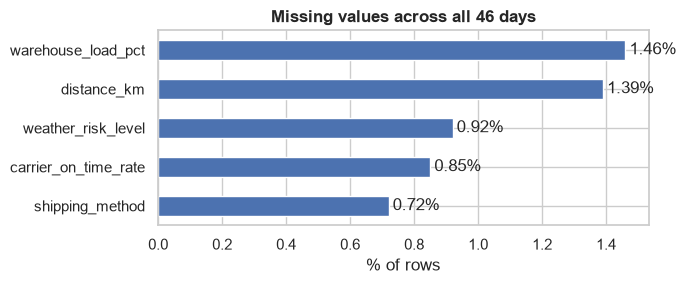

In [7]:
pct = missing.loc[missing["all 46 days"] > 0, "all 46 days (%)"].sort_values()
ax = pct.plot.barh(figsize=(7, 3), color="#4C72B0")
ax.set(title="Missing values across all 46 days", xlabel="% of rows")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.show()

Five columns have gaps of 0.7–1.5 %: three numeric ones and two categorical ones. They're too few to drop rows for. Missing numbers will be **imputed inside the training pipeline**, because a median must be learned on training dates only. Missing categories get an explicit `Unknown` level in Silver.

## Duplicate orders

In [8]:
def duplicate_summary(frame: pd.DataFrame) -> pd.Series:
    return pd.Series({
        "duplicate order_id": int(frame["order_id"].duplicated().sum()),
        "exact duplicate rows": int(frame[list(RAW_COLUMNS)].duplicated().sum()),
    })

dups = pd.DataFrame({d: duplicate_summary(b) for d, b in sample.items()})
dups["all 46 days"] = duplicate_summary(df)
dups

,2026-10-01,2026-10-02,2026-10-03,all 46 days
duplicate order_id,3,3,3,166
exact duplicate rows,3,3,3,166


In [9]:
# Does an order_id ever appear in two different files?
ids_per_order = df.groupby("order_id")["batch_date"].nunique()
print("order_ids found in more than one file:", int((ids_per_order > 1).sum()))

order_ids found in more than one file: 0


Every duplicate is an **exact copy inside the same file**, and no order crosses two days. Keeping the first row in Silver loses no information.

## Invalid values

`data_dictionary.csv` gives valid ranges: distance and value must be positive, there must be at least one item, the hour must be 0–23, and so on. They are coded once as `NUMERIC_RULES` in `src/schemas.py`, and the pipeline uses the same list.

In [10]:
def invalid_counts(frame: pd.DataFrame) -> pd.Series:
    out = {}
    for rule in NUMERIC_RULES:
        values = pd.to_numeric(frame[rule.column], errors="coerce")
        bad = pd.Series(False, index=values.index)
        if rule.low is not None:
            bad |= values < rule.low if rule.low_inclusive else values <= rule.low
        if rule.high is not None:
            bad |= values > rule.high
        out[rule.column] = int(bad.sum())
    return pd.Series(out)

invalid = pd.DataFrame({d: invalid_counts(b) for d, b in sample.items()})
invalid["all 46 days"] = invalid_counts(df)
invalid

,2026-10-01,2026-10-02,2026-10-03,all 46 days
order_hour,0,0,0,0
distance_km,1,0,3,81
items_count,2,1,0,98
package_weight_kg,0,0,0,0
order_value_egp,0,2,0,55
promised_delivery_days,0,0,0,0
warehouse_load_pct,0,0,0,0
carrier_on_time_rate,0,0,0,0


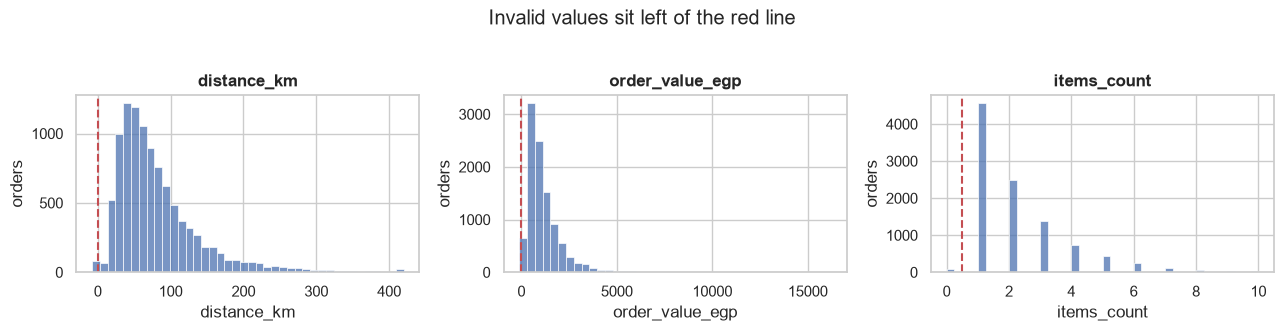

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, ["distance_km", "order_value_egp", "items_count"]):
    sns.histplot(df[col], bins=40, ax=ax, color="#4C72B0")
    ax.axvline(0.5 if col == "items_count" else 0, color="#C44E52", ls="--", lw=1.5)
    ax.set(title=col, ylabel="orders")
fig.suptitle("Invalid values sit left of the red line", y=1.03)
plt.tight_layout()
plt.show()

Three columns break their rules: negative distances, negative order values, and zero-item orders. These values are errors, not information, so Silver turns them into **missing**, and the training pipeline then imputes them like any other gap.

## Category consistency

In [12]:
for col in CATEGORICAL_FEATURES:
    counts = df[col].value_counts(dropna=False)
    print(f"{col}: {len(counts)} distinct values")
    print(counts.to_string(), end="\n\n")

customer_region: 6 distinct values
customer_region
Cairo          2885
Giza           1991
Delta          1919
Alexandria     1690
Upper_Egypt    1016
Canal           718

warehouse_id: 4 distinct values
warehouse_id
WH-04    2632
WH-03    2546
WH-01    2545
WH-02    2496

shipping_method: 7 distinct values
shipping_method
Standard      5907
Express       2974
Same_Day       976
 standard      185
EXPRESS         80
NaN             74
same_day        23

weather_risk_level: 4 distinct values
weather_risk_level
Low       5165
Medium    3436
High      1524
NaN         94



`shipping_method` has spelling variants (`' standard '`, `EXPRESS`, `same_day`) on top of the three real methods. Silver maps them to `Standard`, `Express` and `Same_Day`, ignoring case, spaces and dashes. The other categoricals are clean apart from missing weather values.

## Dates and labels

In [13]:
print("order_date different from its file date:", int((df["order_date"] != df["batch_date"]).sum()))
print("labels:", df[TARGET].value_counts().sort_index().to_dict())

order_date different from its file date: 0
labels: {0: 7800, 1: 2419}


Every `order_date` matches its file, and every label is 0 or 1. Silver and Gold validation still check both, so a bad future file fails loudly.

# Class Distribution

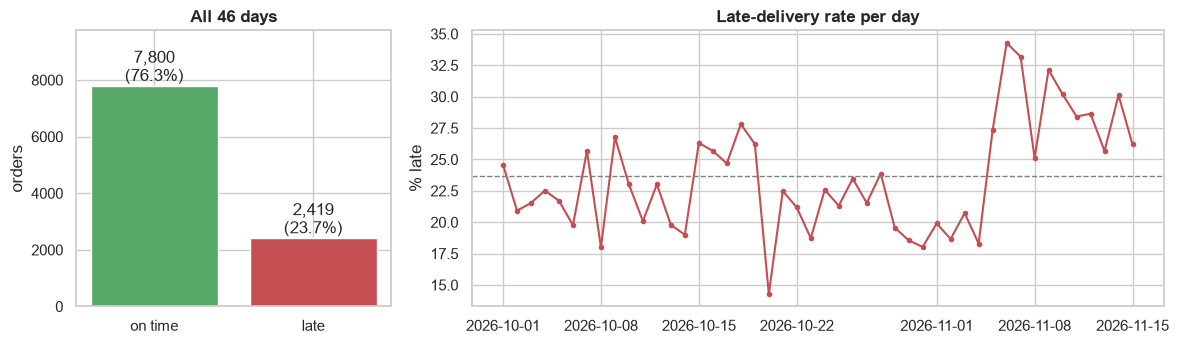

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})

counts = df[TARGET].map(LABELS).value_counts()
axes[0].bar(counts.index, counts.values, color=["#55A868", "#C44E52"])
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:,}\n({v / len(df):.1%})" for v in counts.values])
axes[0].set(title="All 46 days", ylabel="orders", ylim=(0, counts.max() * 1.25))

daily = df.groupby("batch_date")[TARGET].mean().mul(100)
axes[1].plot(pd.to_datetime(daily.index), daily.values, marker="o", ms=3, color="#C44E52")
axes[1].axhline(df[TARGET].mean() * 100, ls="--", color="grey", lw=1)
axes[1].set(title="Late-delivery rate per day", ylabel="% late")
plt.tight_layout()
plt.show()

In [15]:
pd.DataFrame({
    d: {"rows": len(b), "late": int(b[TARGET].sum()), "late %": round(b[TARGET].mean() * 100, 1)}
    for d, b in sample.items()
}).T

,rows,late,late %
2026-10-01,183.0,45.0,24.6
2026-10-02,196.0,41.0,20.9
2026-10-03,209.0,45.0,21.5


About **3 in 4 orders arrive on time** (76.3 % vs 23.7 %): the classes are imbalanced, so the model uses `class_weight="balanced"` and recall on late orders is reported.

The daily late rate is **not stable**. It stays between 14 % and 28 % (mostly around 20–25 %) in October, then **jumps to 25–34 % from 2026-11-06**. That drift is exactly why the split is **time-based** (train on earlier days, test on later ones). A random split would mix November into training and hide it, while a time split shows how a model trained on the past copes with a changing future.

## Daily volume

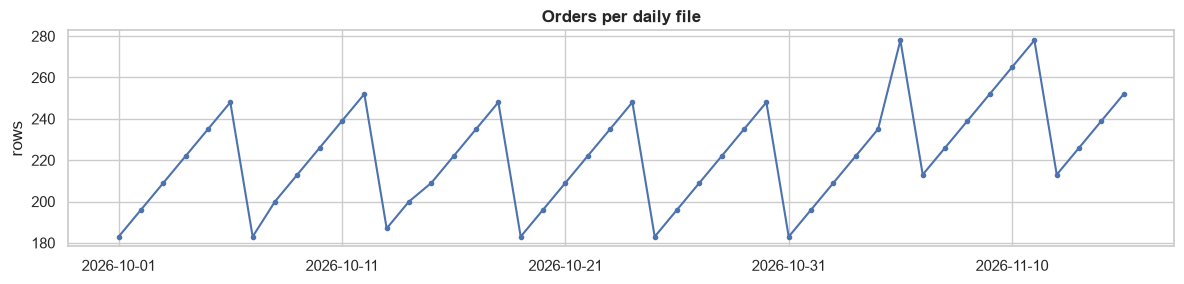

In [16]:
volume = df.groupby("batch_date").size()
ax = volume.plot(figsize=(12, 3), marker="o", ms=3, color="#4C72B0")
ax.set(title="Orders per daily file", xlabel="", ylabel="rows")
plt.tight_layout()
plt.show()

Volume follows a repeating cycle of about six days, with each day larger than the one before. November files are larger, about 213–278 rows instead of 183–252. Each file is small, so a single day is a weak test set, and the model is evaluated on the **latest 20 % of days together**.

# Patterns on Cleaned Data

The rest of the notebook applies the **same Silver rules as the pipeline**: `clean_orders` and then `add_features` from `src/etl.py`. Distributions are therefore not distorted by duplicates or invalid values.

In [17]:
silver = pd.concat([clean_orders(b, pd.Timestamp(d).date())[0] for d, b in batches.items()], ignore_index=True)
gold = add_features(silver)
gold["label"] = gold[TARGET].map(LABELS)
print(f"raw {len(df):,} rows -> silver/gold {len(gold):,} rows")
gold[numeric_cols].describe().T.round(2)

raw 10,219 rows -> silver/gold 10,053 rows


,count,mean,std,min,25%,50%,75%,max
order_hour,10053.0,11.580225,6.908205,0.0,6.0,12.0,18.0,23.0
distance_km,9831.0,82.199502,58.816049,5.8,42.7,66.3,102.6,420.0
items_count,9957.0,2.213418,1.596422,1.0,1.0,2.0,3.0,10.0
package_weight_kg,10053.0,4.583855,2.646482,0.39,2.64,4.06,5.95,23.5
order_value_egp,10000.0,1152.709534,924.801072,90.0,550.8225,893.15,1457.9125,16220.55
promised_delivery_days,10053.0,3.107729,1.381056,1.0,2.0,3.0,4.0,5.0
warehouse_load_pct,9906.0,69.355825,12.152415,30.0,61.1,69.3,77.6,99.0
carrier_on_time_rate,9967.0,0.82933,0.069535,0.6,0.783,0.83,0.878,0.99


## Numeric features by class

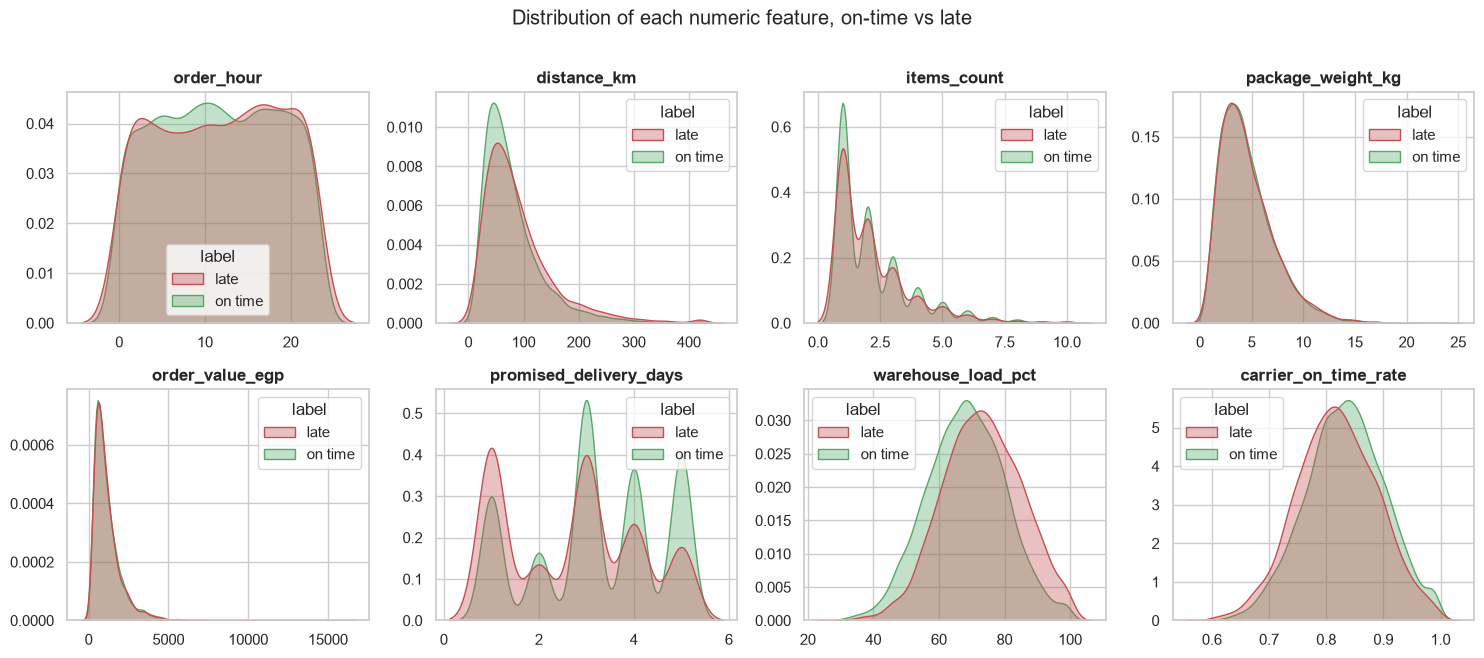

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.flat, numeric_cols):
    sns.kdeplot(data=gold, x=col, hue="label", common_norm=False, fill=True,
                alpha=0.35, ax=ax, palette={"on time": "#55A868", "late": "#C44E52"})
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Distribution of each numeric feature, on-time vs late", y=1.01)
plt.tight_layout()
plt.show()

The clearest separation is **warehouse load**: late orders come from busier warehouses. **Short delivery promises** (1 day) are also over-represented among late orders, while 5-day promises are mostly on time. Late orders lean slightly towards **longer distances** and **lower carrier on-time rates**. Order hour, package weight, item count and order value overlap almost completely between the two classes.

## Late rate by category

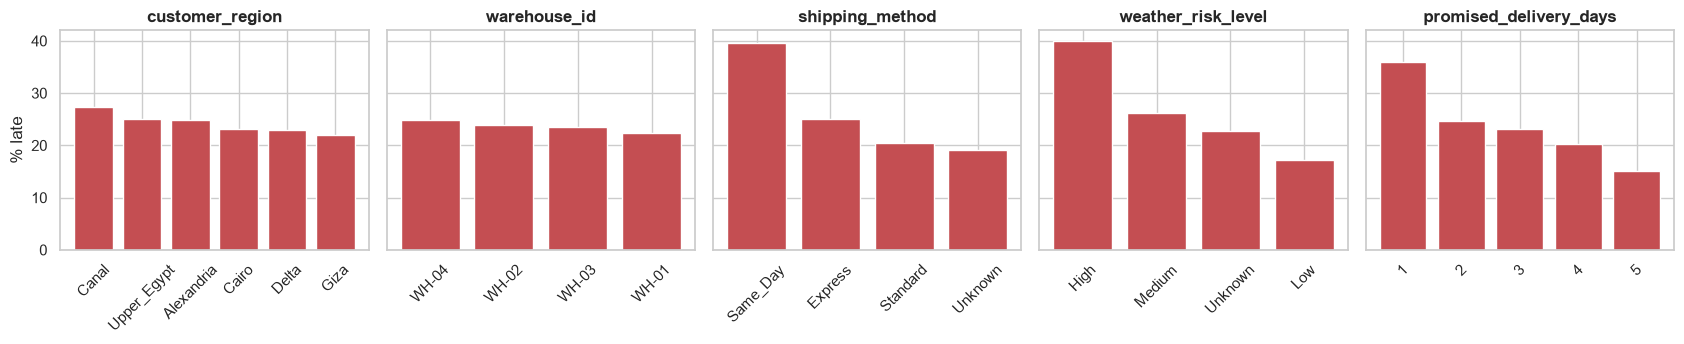

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharey=True)
for ax, col in zip(axes, [*CATEGORICAL_FEATURES, "promised_delivery_days"]):
    rate = gold.groupby(col)[TARGET].mean().mul(100).sort_values(ascending=False)
    ax.bar(rate.index.astype(str), rate.values, color="#C44E52")
    ax.set(title=col, ylabel="% late" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Three inputs separate the classes clearly:
- **Weather risk**: about 40 % late at *High* vs about 17 % at *Low*.
- **Shipping method**: about 40 % for *Same_Day* vs about 20 % for *Standard*.
- **Promised days**: about 36 % at 1 day vs about 15 % at 5 days.

In each case, faster promises and riskier conditions mean more late orders. Region (22–27 %) and warehouse (22–25 %) barely matter. The categoricals go to the model one-hot encoded.

## Correlations

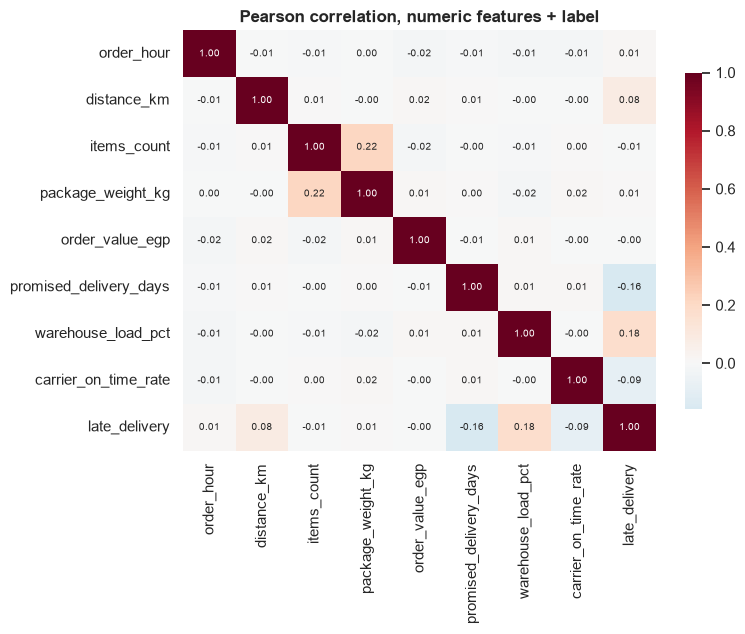

In [20]:
corr = gold[[*numeric_cols, TARGET]].corr(numeric_only=True)
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.title("Pearson correlation, numeric features + label")
plt.tight_layout()
plt.show()

In [21]:
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("corr with late_delivery")

,corr with late_delivery
warehouse_load_pct,0.176
promised_delivery_days,-0.157
carrier_on_time_rate,-0.086
distance_km,0.084
order_hour,0.012
items_count,-0.007
package_weight_kg,0.006
order_value_egp,-0.004


Every linear correlation with the label is **weak** (|r| ≤ 0.18). The strongest are warehouse load (+0.18) and promised days (−0.16). A linear model can therefore only reach modest scores, which is acceptable here because the assignment grades the pipeline, not accuracy. The numeric features are almost uncorrelated with each other (the largest pair is items vs weight, at 0.22), so none of them is redundant.

## Engineered features

Gold adds five row-wise features (`day_of_week`, `is_weekend`, `is_after_cutoff`, `weight_per_item`, `distance_per_promised_day`). They use only the row itself, so they can be computed per day without leakage.

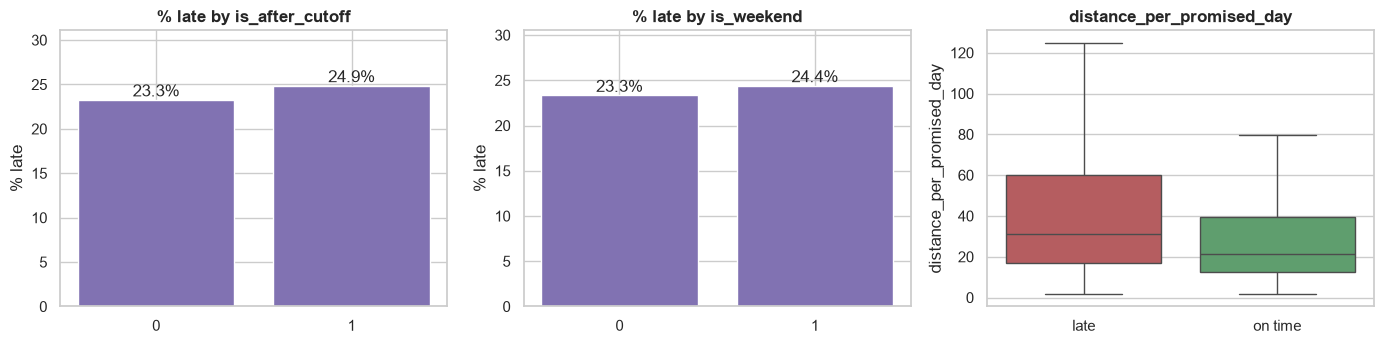

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes[:2], ["is_after_cutoff", "is_weekend"]):
    rate = gold.groupby(col)[TARGET].mean().mul(100)
    ax.bar(rate.index.astype(str), rate.values, color="#8172B2")
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.set(title=f"% late by {col}", ylabel="% late", ylim=(0, rate.max() * 1.25))
sns.boxplot(data=gold, x="label", y="distance_per_promised_day", hue="label",
            palette={"on time": "#55A868", "late": "#C44E52"}, showfliers=False, ax=axes[2], legend=False)
axes[2].set(title="distance_per_promised_day", xlabel="")
plt.tight_layout()
plt.show()

`distance_per_promised_day`, i.e. how tight the delivery promise is, is **clearly higher for late orders**: a median of about 31 vs 21. That supports engineering it rather than leaving distance and the promise as separate features. `is_after_cutoff` and `is_weekend` add only about 1–1.5 points of late rate. They are weak signals, kept because they are cheap and leak-free.

# Raw vs Silver: one batch

In [23]:
raw = sample["2026-10-01"]
clean, dropped, fixed = clean_orders(raw, pd.Timestamp("2026-10-01").date())
print(f"rows: {len(raw)} raw -> {len(clean)} silver")
print("dropped:", {k: v for k, v in dropped.items() if v})
print("fixed:  ", {k: v for k, v in fixed.items() if v})

rows: 183 raw -> 180 silver
dropped: {'duplicate_order_id': 3}
fixed:   {'shipping_method_standardized': 3, 'weather_risk_level_standardized': 2, 'distance_km_invalid_to_missing': 1, 'items_count_invalid_to_missing': 2}


In [24]:
pd.concat({
    "raw": raw["shipping_method"].value_counts(dropna=False),
    "silver": clean["shipping_method"].value_counts(dropna=False),
}, axis=1).fillna(0).astype(int)

,raw,silver
shipping_method,,
Standard,107,108
Express,53,51
Same_Day,20,21
standard,2,0
same_day,1,0


# Conclusions

| Finding | Where it's handled | Why there |
|---|---|---|
| Exact duplicate `order_id`s, inside a single file | **Silver**: keep the first row | Deterministic rule; no information lost |
| Spelling variants in `shipping_method` | **Silver**: map to `Standard` / `Express` / `Same_Day` | Deterministic rule |
| Missing categories (`shipping_method`, `weather_risk_level`) | **Silver**: explicit `Unknown` | An honest level instead of a guess |
| Negative distance or value, zero items | **Silver**: set to missing | Invalid values are errors, not data |
| Wrong dates or labels (none today) | **Silver** drops them; **Gold validation** fails loudly | Protects against future bad files |
| Missing numeric values (about 1 %) | **Training pipeline**: `SimpleImputer(median)` | A median is learned, so it's fitted on training dates only |
| Different scales, categorical inputs | **Training pipeline**: `StandardScaler`, `OneHotEncoder` | Learned on training dates only |
| 76 / 24 class imbalance | **Model**: `class_weight="balanced"` | Keeps recall on late orders |
| Late rate rises from 2026-11-06 (drift) | **Split**: time-based | Train on the past, test on the future; a random split would hide the drift |

The fixed rules live in `src/etl.py`. Every learned step lives in the sklearn `Pipeline` in `src/train.py`.